In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles available:")
for file in os.listdir():
    print(file)

Current folder:
C:\Users\dilee

Files available:
.anaconda
.aws
.azure
.cagent
.conda
.config
.continuum
.copilot
.cursor
.docker
.gemini
.git
.gitconfig
.idlerc
.ipynb_checkpoints
.ipython
.jupyter
.kube
.lesshst
.matplotlib
.minikube
.ollama
.Python_Data_Processing_Assessment.ipynb.layout
.streamlit
.vscode
.vscode-shared
01_Dataset_Understanding.ipynb
01_NumPy_Basics.ipynb
02_Data_Inspection.ipynb
02_NumPy_Math.ipynb
03_Data_Quality.ipynb
03_NumPy_Random.ipynb
04_Pandas_Basics.ipynb
04_Univariate_Analysis.ipynb
05_Bivariate_Analysis.ipynb
05_File_Operations.ipynb
05_Probability.ipynb
06_Data_Inspection.ipynb
06_Probability_Distributions.ipynb
07_Data_Selection.ipynb
07_Sampling.ipynb
08_Correlation.ipynb
08_Data_Manipulation.ipynb
09_GroupBy.ipynb
09_Outliers.ipynb
10_Hypothesis_Testing.ipynb
10_Merging_Data.ipynb
11_Date_Time.ipynb
11_Statistical_Tests.ipynb
12_Feature_Relationships.ipynb
12_String_Operations.ipynb
13_Missing_Values.ipynb
13_Statistical_Visualization.ipynb
14_Perfo

In [5]:
import os
import glob

print("Current folder:", os.getcwd())

print("\nCSV files found:")
print(glob.glob("**/*.csv", recursive=True))

Current folder: C:\Users\dilee

CSV files found:
['employees_output.csv', 'employees_task2.csv', 'students.csv', 'students_1.csv', 'students_2.csv', 'student_analysis.csv', 'student_data.csv', 'titanic_cleaned.csv', 'titanic_feature_engineered.csv', 'titanic_predictions.csv', 'AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\matplotlib\\mpl-data\\sample_data\\data_x_x2_x3.csv', 'AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\matplotlib\\mpl-data\\sample_data\\msft.csv', 'AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\matplotlib\\mpl-data\\sample_data\\Stocks.csv', 'AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\numpy\\random\\tests\\data\\mt19937-testset-1.csv', 'AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\numpy\\random\\tests\\data\\mt19937-testset-2.csv', 'AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\numpy\\random\\tests\\data\\pcg64-testset-1.csv', 'AppData\\Local\\Programs

In [6]:
import seaborn as sns
import pandas as pd

df = sns.load_dataset("tips")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


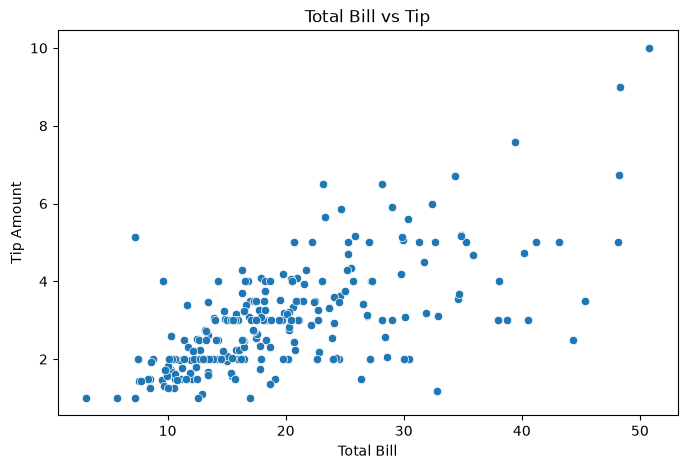

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="total_bill",
    y="tip"
)

plt.title("Total Bill vs Tip")
plt.xlabel("Total Bill")
plt.ylabel("Tip Amount")
plt.show()

In [8]:
correlation = df["total_bill"].corr(df["tip"])

print("Correlation between Total Bill and Tip:", round(correlation, 3))

Correlation between Total Bill and Tip: 0.676


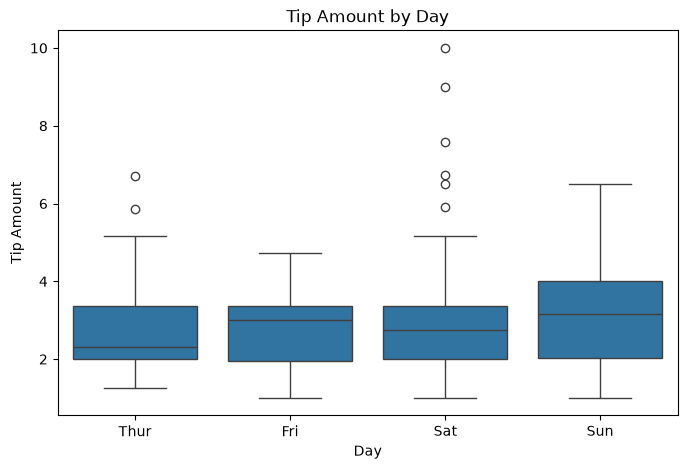

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="day", y="tip")

plt.title("Tip Amount by Day")
plt.xlabel("Day")
plt.ylabel("Tip Amount")
plt.show()

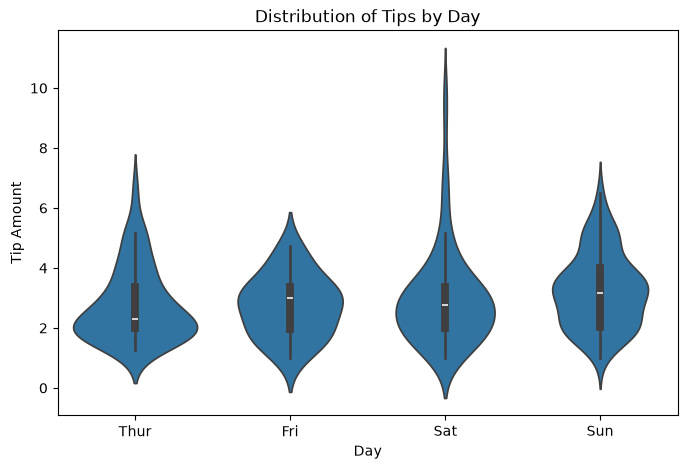

In [10]:
plt.figure(figsize=(8, 5))

sns.violinplot(data=df, x="day", y="tip")

plt.title("Distribution of Tips by Day")
plt.xlabel("Day")
plt.ylabel("Tip Amount")
plt.show()

In [11]:
# Count observations by day and smoker status
cross_table = pd.crosstab(df["day"], df["smoker"])

print("Cross-tabulation: Day vs Smoker")
display(cross_table)

Cross-tabulation: Day vs Smoker


smoker,Yes,No
day,,
Thur,17,45
Fri,15,4
Sat,42,45
Sun,19,57


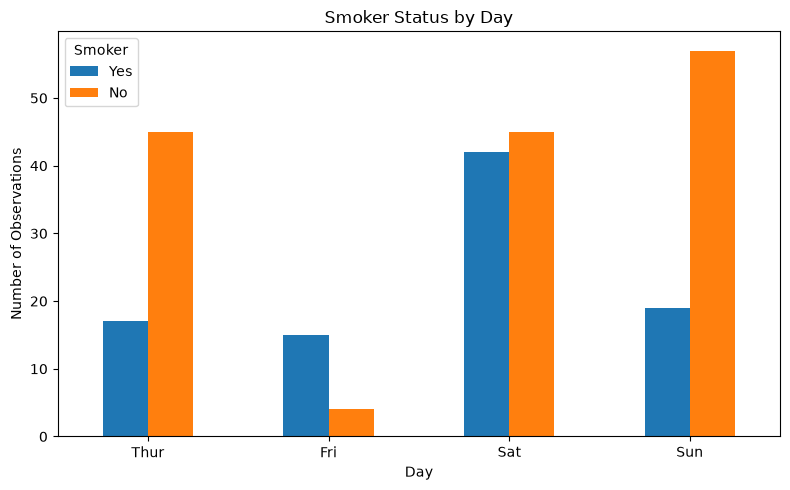

In [12]:
cross_table.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Smoker Status by Day")
plt.xlabel("Day")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.legend(title="Smoker")
plt.tight_layout()
plt.show()

In [13]:
percentage_table = pd.crosstab(
    df["day"],
    df["smoker"],
    normalize="index"
) * 100

print("Percentage distribution by day:")
display(percentage_table.round(2))

Percentage distribution by day:


smoker,Yes,No
day,,
Thur,27.42,72.58
Fri,78.95,21.05
Sat,48.28,51.72
Sun,25.00,75.00


In [14]:
# Select numerical columns
numerical_df = df.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numerical_df.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,total_bill,tip,size
total_bill,1.00,0.68,0.60
tip,0.68,1.00,0.49
size,0.60,0.49,1.00


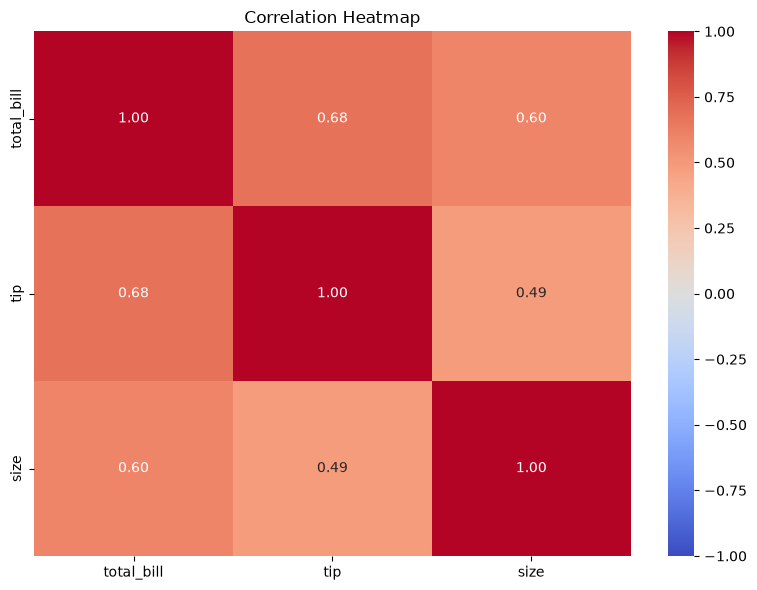

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [16]:
print("BIvariate Analysis Summary")
print("=" * 40)

print("Dataset shape:", df.shape)

print("\nNumerical columns:")
print(df.select_dtypes(include="number").columns.tolist())

print("\nCategorical columns:")
print(
    df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()
)

print("\nCorrelation between total bill and tip:")
print(round(df["total_bill"].corr(df["tip"]), 3))

print("\nBivariate analysis completed successfully!")

BIvariate Analysis Summary
Dataset shape: (244, 7)

Numerical columns:
['total_bill', 'tip', 'size']

Categorical columns:
['sex', 'smoker', 'day', 'time']

Correlation between total bill and tip:
0.676

Bivariate analysis completed successfully!


## Conclusion

Bivariate analysis was performed to understand relationships between pairs of variables. Scatter plots and correlation coefficients were used to examine relationships between numerical variables. Box plots and violin plots compared numerical distributions across categories. Cross-tabulation and grouped bar charts explored relationships between categorical variables. A correlation matrix and heatmap summarized linear relationships among numerical features. These visualizations and statistical methods help identify patterns and support further exploratory data analysis. Correlation indicates association and does not necessarily imply causation.